# NB7 — Counterfactual XAI (GeoGraphNet, EuroSAT-MS)
**Inputs (Datasets only, no notebooks):** `eurosat-geograph-nb1-v2`, `eurosat-geograph-nb3-v2`, `eurosat-geograph-nb4-v2-output`, `nb2-eurosat-output`. GPU T4 on. Internet not required.

Models: A3, A4, A5 (Phase 1 checkpoints) + B2 (16-ch CNN, occlusion/random only). Subset: 100 test patches per class from fold 0.
**Fidelity+** = p(full) − p(top-k superpixels removed) (higher = better). **Fidelity−** = p(full) − p(only top-k kept) (lower = better). Removed region = training mean (0 after normalisation); original segmentation kept; node features, edge attributes and spectral k-NN edges are **recomputed from the masked image**.
Statistics use only patches the model classifies correctly when unmasked. Attention weight is not causal importance; occlusion is the reference.

In [1]:
!pip install -q torch_geometric


In [2]:
import os, sys, json, glob, random, time
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(dev, torch.__version__)

def find_one(name):
    hits = glob.glob("/kaggle/input/**/" + name, recursive=True)
    assert len(hits) == 1, (name, hits)          # never silently take the first match
    return hits[0]

for n in ["geograph_graph.py", "geograph_model.py"]:
    sys.path.insert(0, os.path.dirname(find_one(n)))
import geograph_graph as gg
from geograph_model import (GeoGraphNet, GraphDataset, graph_stats, collate, EXPERIMENTS)

N_PER_CLASS = 100
KS = [1, 2, 3, 5]
OUT = "/kaggle/working"
random.seed(42); np.random.seed(42); torch.manual_seed(42)

cuda 2.11.0+cu130


In [3]:
X16 = np.load(find_one("X16_float16.npy"), mmap_mode="r")
labels = np.load(find_one("labels.npy"))
fd = pd.read_csv(find_one("folds.csv")); print(fd.columns.tolist(), len(fd))
fcol = [c for c in fd.columns if "fold" in c.lower()][0]
fold = fd[fcol].values
test_idx = np.where(fold == 0)[0]
train_idx = np.where(np.isin(fold, [2, 3, 4]))[0]
print(X16.shape, len(test_idx), len(train_idx))
G = dict(np.load(find_one("graphs_K25_m20.npz")))
print({k: v.shape for k, v in G.items()})

cs = json.load(open(find_one("channel_stats.json"))); print(list(cs.keys())[:12])
MU = SD = None
for a, b in [("mean", "std"), ("train_mean", "train_std"), ("phase1_mean", "phase1_std")]:
    if a in cs and b in cs:
        MU, SD = np.array(cs[a], np.float32), np.array(cs[b], np.float32); print("stats from json:", a, b)
        break
if MU is None:                                    # fallback: recompute on Phase-1 training folds only
    s1 = np.zeros(16); s2 = np.zeros(16); cnt = 0
    for i in range(0, len(train_idx), 500):
        xb = np.asarray(X16[train_idx[i:i+500]], np.float64)
        s1 += xb.sum((0, 2, 3)); s2 += (xb ** 2).sum((0, 2, 3)); cnt += xb.shape[0] * 4096
    MU = (s1 / cnt).astype(np.float32); SD = np.sqrt(s2 / cnt - (s1 / cnt) ** 2).astype(np.float32)
    print("stats recomputed from training folds 2,3,4")
assert MU.shape == (16,) and SD.shape == (16,)
print(np.round(MU, 4))

['rel', 'class', 'label', 'fold', 'phase1'] 27000
(27000, 16, 64, 64) 5400 16200
{'seg': (27000, 64, 64), 'n_nodes': (27000,), 'node_ptr': (27001,), 'node_static': (599733, 36), 'edge_ptr': (27001,), 'edge_index': (2, 4361363), 'edge_attr': (4361363, 3), 'edge_type': (4361363,)}
['channels', 'phase1_train_folds_2_3_4', 'cv_train_excluding_fold']
stats recomputed from training folds 2,3,4
[ 0.1354  0.1118  0.1043  0.0947  0.1199  0.2001  0.2372  0.2299  0.073
  0.0012  0.1819  0.1117  0.2598  0.3477 -0.282  -0.1765]


In [4]:
BASE = dict(D=128, heads=4, layers=2, drop=0.2, backbone="tf_efficientnetv2_s.in21k_ft_in1k", img_size=64)
def load_sd(p):
    o = torch.load(p, map_location="cpu")
    if isinstance(o, dict):
        for k in ("model", "state_dict", "model_state_dict", "sd"):
            if k in o and isinstance(o[k], dict): return o[k]
    return o

models = {}
for c in ["A3", "A4", "A5"]:
    m = GeoGraphNet(dict(BASE, **EXPERIMENTS[c])).to(dev)
    m.load_state_dict(load_sd(find_one(f"best_{c}_K25m20.pt")), strict=True); m.eval(); models[c] = m
    print(c, "loaded")

try:
    import timm
    b2 = timm.create_model(BASE["backbone"], pretrained=False, num_classes=10, in_chans=16, drop_rate=0.2)
    b2.load_state_dict(load_sd(find_one("best_B2_16ch_cnn.pt")), strict=True); models["B2"] = b2.to(dev).eval(); print("B2 loaded")
except Exception as e:
    print("B2 NOT loaded (paste NB2's B2 model builder to fix):", repr(e)[:300])
SPEC = {"A3": False, "A4": True, "A5": True}
GM = [c for c in models if c != "B2"]

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


A3 loaded


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


A4 loaded


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


A5 loaded
B2 loaded


In [5]:
NSTAT = {s: graph_stats(G, train_idx, s) for s in (False, True)}

def build_fixed(x, lab, k_spec=3):
    # same as geograph_graph.build_graph but with a FIXED segmentation (no SLIC re-run)
    x = np.asarray(x, np.float32); n = int(lab.max()) + 1
    l = lab.ravel().astype(np.int64); xf = x.reshape(16, -1)
    cnt = np.bincount(l, minlength=n).astype(np.float64)
    mean = np.stack([np.bincount(l, weights=xf[c], minlength=n) for c in range(16)], 1) / cnt[:, None]
    sq = np.stack([np.bincount(l, weights=xf[c] ** 2, minlength=n) for c in range(16)], 1) / cnt[:, None]
    std = np.sqrt(np.maximum(sq - mean ** 2, 0))
    yy, xx = np.mgrid[0:64, 0:64]
    cx = np.bincount(l, weights=xx.ravel().astype(np.float64), minlength=n) / cnt / 63.0
    cy = np.bincount(l, weights=yy.ravel().astype(np.float64), minlength=n) / cnt / 63.0
    M = gg.adjacency(lab, n)
    border = (np.bincount(lab[0, :], minlength=n) + np.bincount(lab[-1, :], minlength=n) +
              np.bincount(lab[:, 0], minlength=n) + np.bincount(lab[:, -1], minlength=n))
    P = M.sum(1) + border
    node = np.concatenate([mean, std, cx[:, None], cy[:, None], (cnt / 4096.0)[:, None], (P / cnt)[:, None]], 1).astype(np.float32)
    u = mean[:, :13]; u = u / (np.linalg.norm(u, axis=1, keepdims=True) + 1e-6)
    S = np.arccos(np.clip(u @ u.T, -1.0, 1.0))
    D = np.sqrt((cx[:, None] - cx[None, :]) ** 2 + (cy[:, None] - cy[None, :]) ** 2)
    di, sj = np.nonzero(M > 0)
    sp_attr = np.stack([D[di, sj], S[di, sj], M[di, sj] / P[di]], 1)
    kk = min(k_spec, n - 1)
    Sm = S.copy(); Sm[M > 0] = np.inf; np.fill_diagonal(Sm, np.inf)
    nn = np.argsort(Sm, axis=1)[:, :kk]
    di2 = np.repeat(np.arange(n), kk); sj2 = nn.ravel()
    keep = np.isfinite(Sm[di2, sj2]); di2, sj2 = di2[keep], sj2[keep]
    sc_attr = np.stack([D[di2, sj2], S[di2, sj2], np.zeros(len(di2))], 1)
    ei = np.stack([np.concatenate([sj, sj2]), np.concatenate([di, di2])]).astype(np.int64)
    ea = np.concatenate([sp_attr, sc_attr]).astype(np.float32)
    et = np.concatenate([np.zeros(len(di)), np.ones(len(di2))]).astype(np.int8)
    return node, ei, ea, et

def mask_nodes(x, lab, S):
    if not S: return x
    y = x.copy(); y[:, np.isin(lab, list(S))] = MU[:, None]; return y

def norm_img(xm): return ((xm - MU[:, None, None]) / (SD[:, None, None] + 1e-6)).astype(np.float32)

def make_item(xm, lab, spec, y, g=None):
    node, ei, ea, et = g if g is not None else build_fixed(xm, lab)
    if not spec:
        k = et == 0; ei, ea = ei[:, k], ea[k]
    nmu, nsd, emu, esd = NSTAT[spec]
    return (norm_img(xm), lab.astype(np.int64), (node - nmu) / nsd, ei.astype(np.int64), (ea - emu) / esd, y)

@torch.no_grad()
def run_graph(model, items, bs=256, want_attn=False):
    P, A = [], []
    for i in range(0, len(items), bs):
        ch = items[i:i + bs]
        b = {k: v.to(dev) for k, v in collate(ch).items()}
        P.append(F.softmax(model(b).float(), 1).cpu().numpy())
        if want_attn:
            a = model.last_attn.cpu().numpy(); A += np.split(a, np.cumsum([len(it[2]) for it in ch])[:-1])
    return np.concatenate(P), A

@torch.no_grad()
def run_cnn(model, imgs, bs=256):
    P = []
    for i in range(0, len(imgs), bs):
        x = torch.from_numpy(np.stack(imgs[i:i + bs])).to(dev)
        P.append(F.softmax(model(x).float(), 1).cpu().numpy())
    return np.concatenate(P)

In [6]:
# ---- sanity checks (all must pass before any XAI number is trusted)
chk = test_idx[:64]
for r in chk[:5]:
    x = np.asarray(X16[r], np.float32); lab = G["seg"][r].astype(np.int64)
    node, ei, ea, et = build_fixed(x, lab); g = gg.get_graph(G, int(r))
    assert np.allclose(node, g["node"], atol=2e-3) and np.array_equal(ei, g["ei"]) and np.allclose(ea, g["ea"], atol=2e-3), r
print("check A ok: rebuilt graph == cached graph")
saved = np.load(find_one("nb4_probs.npz"))
for c in GM:
    spec = SPEC[c]
    ds = GraphDataset(chk, G, X16, labels, MU, SD, NSTAT[spec], spec, False)
    P1, _ = run_graph(models[c], [ds[i] for i in range(len(ds))])
    its = [make_item(np.asarray(X16[r], np.float32), G["seg"][r].astype(np.int64), spec, int(labels[r])) for r in chk]
    P2, _ = run_graph(models[c], its)
    assert np.abs(P1 - P2).max() < 1e-2, (c, np.abs(P1 - P2).max())
    ag = (P2.argmax(1) == saved["test_" + c][:64].argmax(1)).mean()
    print(c, "check B ok (own pipeline == dataset pipeline); argmax agreement with nb4_probs:", ag)
    assert ag >= 0.98
print("all checks passed")

check A ok: rebuilt graph == cached graph
A3 check B ok (own pipeline == dataset pipeline); argmax agreement with nb4_probs: 1.0
A4 check B ok (own pipeline == dataset pipeline); argmax agreement with nb4_probs: 1.0
A5 check B ok (own pipeline == dataset pipeline); argmax agreement with nb4_probs: 1.0
all checks passed


In [7]:
rng0 = np.random.default_rng(0)
sub = np.concatenate([rng0.choice(test_idx[labels[test_idx] == c], N_PER_CLASS, replace=False) for c in range(10)])
VIZ = [int(sub[c * N_PER_CLASS]) for c in (0, 1, 3, 5, 7, 9)]; viz = {}
rows = []

def patch_eval(r):
    x = np.asarray(X16[r], np.float32); lab = G["seg"][r].astype(np.int64); n = int(lab.max()) + 1; y = int(labels[r])
    if n < 3: return
    cache = {}
    def mk(S):
        key = frozenset(S)
        if key not in cache:
            xm = mask_nodes(x, lab, key); cache[key] = (xm, build_fixed(xm, lab))
        return cache[key]
    rand_order = np.random.default_rng(int(r)).permutation(n)
    for c in models:
        spec = SPEC.get(c, False)
        sets = [frozenset()] + [frozenset([j]) for j in range(n)]
        if c == "B2":
            P = run_cnn(models[c], [norm_img(mk(S)[0]) for S in sets]); attn = None
        else:
            P, A = run_graph(models[c], [make_item(mk(S)[0], lab, spec, y, mk(S)[1]) for S in sets], want_attn=True); attn = A[0]
        p_full = float(P[0, y]); correct = int(P[0].argmax() == y)
        occl = p_full - P[1:, y]
        orders = {"occlusion": np.argsort(-occl), "random": rand_order}
        if attn is not None: orders["attention"] = np.argsort(-attn)
        if c == "A4" and r in VIZ: viz[r] = dict(lab=lab, x=x, attn=attn, occl=occl, p_full=p_full)
        var, meta = [], []
        for meth, order in orders.items():
            for k in KS:
                ke = max(1, min(k, n - 1)); top = set(order[:ke].tolist()); bot = set(order[-ke:].tolist()); keep = set(range(n)) - top
                for kind, S in (("remove_top", top), ("remove_bottom", bot), ("keep_top", keep)):
                    var.append(frozenset(S)); meta.append((meth, k, kind))
        if c == "B2": Q = run_cnn(models[c], [norm_img(mk(S)[0]) for S in var])
        else: Q, _ = run_graph(models[c], [make_item(mk(S)[0], lab, spec, y, mk(S)[1]) for S in var])
        res = {}
        for (meth, k, kind), q in zip(meta, Q[:, y]): res[(meth, k, kind)] = float(q)
        for meth in orders:
            for k in KS:
                rows.append(dict(patch=int(r), cls=y, n=n, model=c, method=meth, k=k, p_full=p_full, correct=correct,
                                 p_remove_top=res[(meth, k, "remove_top")], p_remove_bottom=res[(meth, k, "remove_bottom")],
                                 p_keep_top=res[(meth, k, "keep_top")]))

t0 = time.time()
for r in tqdm(sub):
    patch_eval(int(r))
print("done in %.1f min" % ((time.time() - t0) / 60))
df = pd.DataFrame(rows)
df["fid_plus"] = df.p_full - df.p_remove_top; df["fid_minus"] = df.p_full - df.p_keep_top; df["drop_bottom"] = df.p_full - df.p_remove_bottom
df.to_csv(f"{OUT}/nb7_fidelity_raw.csv", index=False)

  0%|          | 0/1000 [00:00<?, ?it/s]

done in 8.1 min


k                    1      2      3      5
method    model                            
attention A3     0.024  0.069  0.125  0.251
          A4     0.026  0.064  0.104  0.194
          A5     0.020  0.045  0.082  0.166
occlusion A3     0.067  0.132  0.172  0.235
          A4     0.063  0.117  0.142  0.193
          A5     0.048  0.098  0.124  0.164
          B2     0.170  0.227  0.262  0.319
random    A3     0.010  0.034  0.064  0.148
          A4     0.009  0.027  0.054  0.120
          A5     0.003  0.017  0.038  0.095
          B2     0.034  0.082  0.126  0.209

k                    1      2      3      5
method    model                            
attention A3     0.806  0.797  0.772  0.674
          A4     0.794  0.788  0.758  0.646
          A5     0.812  0.799  0.764  0.621
occlusion A3     0.806  0.799  0.785  0.720
          A4     0.795  0.791  0.777  0.710
          A5     0.812  0.802  0.782  0.694
          B2     0.797  0.789  0.763  0.672
random    A3     0.804  0.804  

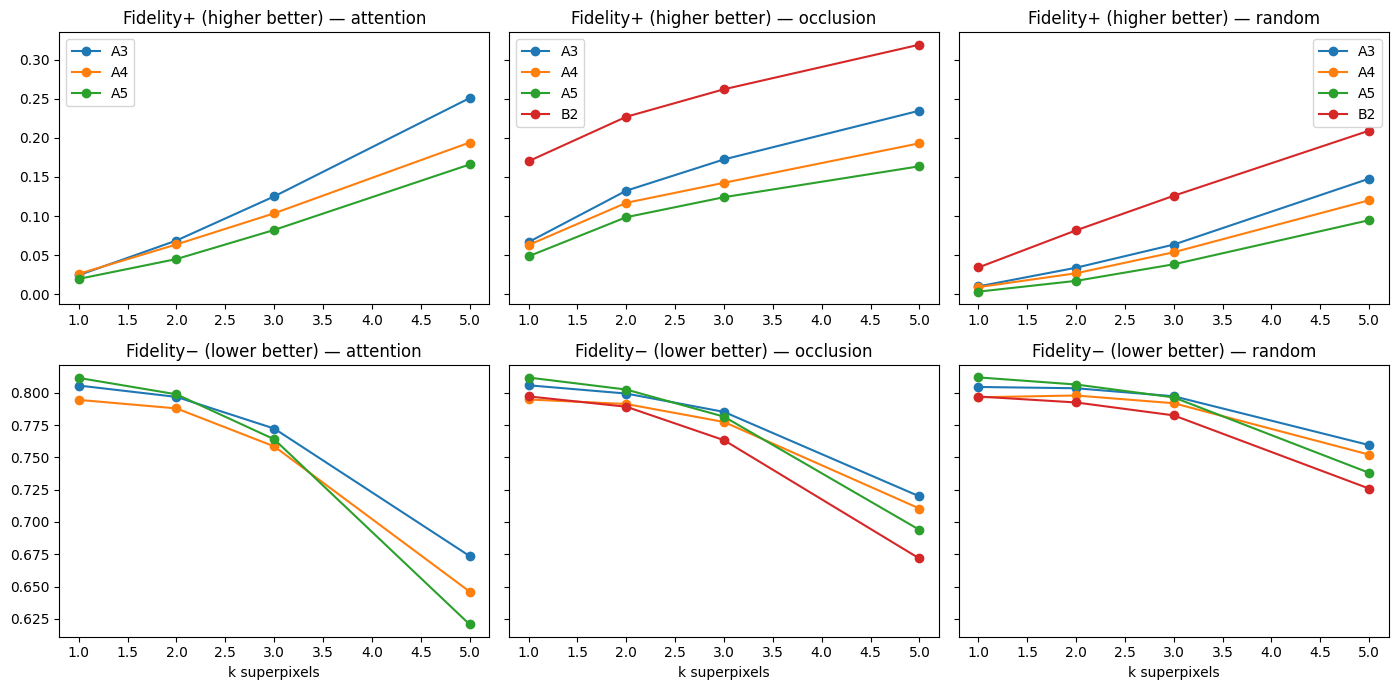

In [8]:
d = df[df.correct == 1]
summ = d.groupby(["model", "method", "k"]).agg(n=("patch", "nunique"), fid_plus=("fid_plus", "mean"), fid_minus=("fid_minus", "mean"),
                                               drop_bottom=("drop_bottom", "mean"), fid_plus_se=("fid_plus", lambda s: s.std() / np.sqrt(len(s)))).round(4).reset_index()
summ.to_csv(f"{OUT}/nb7_fidelity_summary.csv", index=False)
print(summ.pivot_table(index=["method", "model"], columns="k", values="fid_plus").round(3).to_string())
print(); print(summ.pivot_table(index=["method", "model"], columns="k", values="fid_minus").round(3).to_string())
print(); print(summ.pivot_table(index=["method", "model"], columns="k", values="drop_bottom").round(3).to_string())
meths = ["attention", "occlusion", "random"]
fig, ax = plt.subplots(2, 3, figsize=(14, 7), sharey="row")
for j, meth in enumerate(meths):
    for c in models:
        s = summ[(summ.method == meth) & (summ.model == c)]
        if len(s) == 0: continue
        ax[0, j].plot(s.k, s.fid_plus, marker="o", label=c); ax[1, j].plot(s.k, s.fid_minus, marker="o", label=c)
    ax[0, j].set_title(f"Fidelity+ (higher better) — {meth}"); ax[1, j].set_title(f"Fidelity− (lower better) — {meth}")
    ax[1, j].set_xlabel("k superpixels"); ax[0, j].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/nb7_fidelity.png", dpi=150); plt.show()

In [9]:
GROUPS = {"none": [], "RGB": [3, 2, 1], "RedEdge": [4, 5, 6, 12], "NIR": [7], "SWIR": [10, 11], "Indices": [13, 14, 15], "B1_B9_B10": [0, 8, 9]}
brow = []
for gname, chs in GROUPS.items():
    gx = []
    for r in sub:
        x = np.asarray(X16[int(r)], np.float32).copy()
        if chs: x[chs] = MU[chs][:, None, None]
        gx.append((int(r), x, G["seg"][int(r)].astype(np.int64), int(labels[int(r)])))
    gb = [build_fixed(x, lab) for _, x, lab, _ in gx]
    yy = np.array([t[3] for t in gx])
    for c in models:
        if c == "B2": P = run_cnn(models[c], [norm_img(x) for _, x, _, _ in gx])
        else: P, _ = run_graph(models[c], [make_item(x, lab, SPEC[c], y, g) for (_, x, lab, y), g in zip(gx, gb)])
        brow.append(dict(group=gname, model=c, acc=100 * (P.argmax(1) == yy).mean(), p_true=P[np.arange(len(yy)), yy].mean()))
band = pd.DataFrame(brow).round(3)
band.to_csv(f"{OUT}/nb7_band_occlusion.csv", index=False)
print(band.pivot(index="group", columns="model", values="acc").to_string())
print(); print(band.pivot(index="group", columns="model", values="p_true").to_string())

model        A3    A4    A5    B2
group                            
B1_B9_B10  97.1  97.0  97.9  96.3
Indices    92.9  94.6  92.8  91.6
NIR        92.4  92.2  92.9  92.9
RGB        87.0  84.5  86.1  85.4
RedEdge    97.3  97.0  97.5  96.1
SWIR       98.1  97.9  97.8  95.2
none       98.4  98.6  98.8  97.5

model         A3     A4     A5     B2
group                                
B1_B9_B10  0.877  0.882  0.893  0.857
Indices    0.827  0.852  0.837  0.788
NIR        0.829  0.838  0.846  0.818
RGB        0.769  0.754  0.773  0.735
RedEdge    0.882  0.886  0.893  0.857
SWIR       0.893  0.897  0.897  0.851
none       0.899  0.905  0.908  0.884


  0%|          | 0/22 [00:00<?, ?it/s]

gate = weight of CNN vector.  mean 0.5029  std 0.0616  min 0.3982  max 0.6118
quantiles 1/5/25/50/75/95/99%: [0.4018 0.4047 0.4534 0.5244 0.5606 0.5833 0.5901]
mean gate correct 0.5024 | wrong 0.5424 (n wrong = 59)
                        mean     std
cls                                 
AnnualCrop            0.5688  0.0072
Forest                0.4062  0.0053
HerbaceousVegetation  0.5322  0.0090
Highway               0.5049  0.0137
Industrial            0.5410  0.0079
Pasture               0.4583  0.0153
PermanentCrop         0.5610  0.0064
Residential           0.4665  0.0099
River                 0.5836  0.0065
SeaLake               0.4209  0.0091


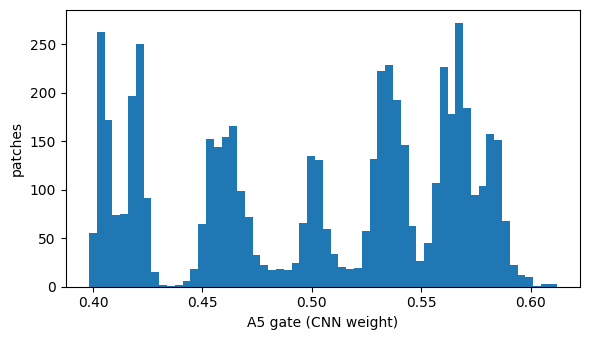

In [10]:
# ---- A5 per-patch gate (full test fold, 5400 patches)
m5 = models["A5"]
ds = GraphDataset(test_idx, G, X16, labels, MU, SD, NSTAT[True], True, False)
dl = torch.utils.data.DataLoader(ds, batch_size=256, shuffle=False, collate_fn=collate, num_workers=2)
gate, pred, ytrue = [], [], []
with torch.no_grad():
    for b in tqdm(dl):
        b = {k: v.to(dev) for k, v in b.items()}
        lo = m5(b); gate.append(m5.last_gate.cpu().numpy()); pred.append(lo.argmax(1).cpu().numpy()); ytrue.append(b["y"].cpu().numpy())
gate, pred, ytrue = map(np.concatenate, (gate, pred, ytrue)); ok = pred == ytrue
print("gate = weight of CNN vector.  mean %.4f  std %.4f  min %.4f  max %.4f" % (gate.mean(), gate.std(), gate.min(), gate.max()))
print("quantiles 1/5/25/50/75/95/99%:", np.round(np.quantile(gate, [.01, .05, .25, .5, .75, .95, .99]), 4))
print("mean gate correct %.4f | wrong %.4f (n wrong = %d)" % (gate[ok].mean(), gate[~ok].mean(), (~ok).sum()))
cls = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial", "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
gc = pd.DataFrame(dict(cls=[cls[i] for i in ytrue], gate=gate)).groupby("cls").gate.agg(["mean", "std"]).round(4); print(gc)
gc.to_csv(f"{OUT}/nb7_gate_by_class.csv"); np.savez(f"{OUT}/nb7_gate_per_patch.npz", gate=gate, pred=pred, y=ytrue)
plt.figure(figsize=(6, 3.5)); plt.hist(gate, bins=60); plt.xlabel("A5 gate (CNN weight)"); plt.ylabel("patches"); plt.tight_layout()
plt.savefig(f"{OUT}/nb7_gate_hist.png", dpi=150); plt.show()

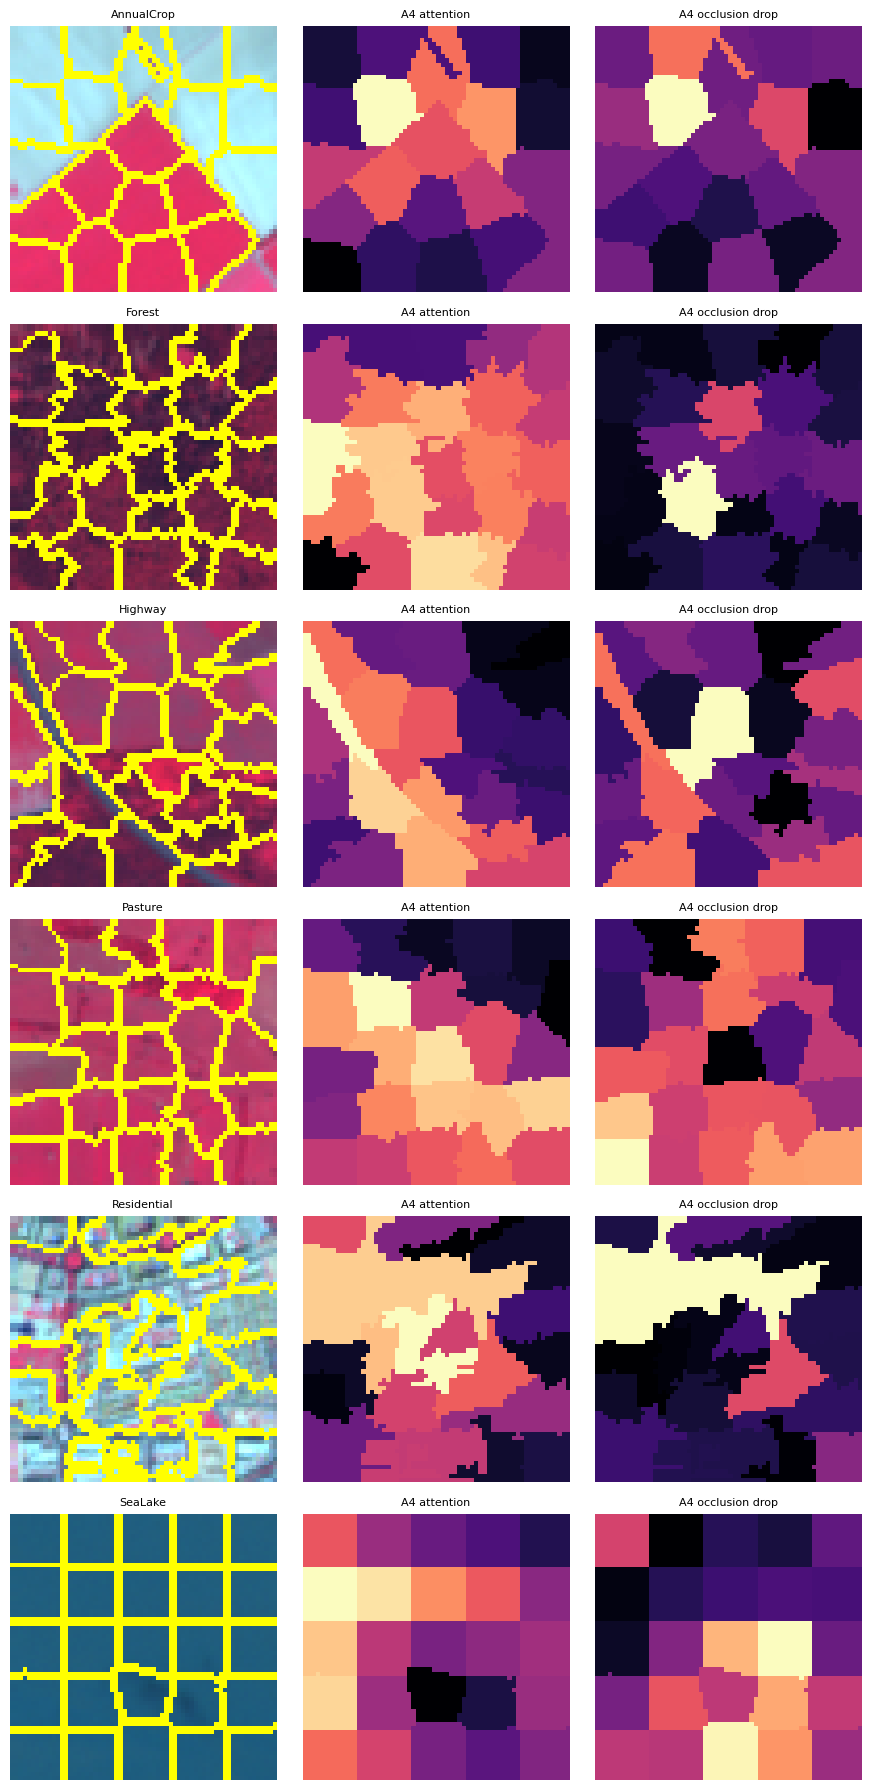

['__notebook__.ipynb', 'nb7_band_occlusion.csv', 'nb7_examples.png', 'nb7_fidelity.png', 'nb7_fidelity_raw.csv', 'nb7_fidelity_summary.csv', 'nb7_gate_by_class.csv', 'nb7_gate_hist.png', 'nb7_gate_per_patch.npz']


In [11]:
from skimage.segmentation import mark_boundaries
ids = [r for r in VIZ if r in viz]
fig, ax = plt.subplots(len(ids), 3, figsize=(9, 3 * len(ids)))
for i, r in enumerate(ids):
    v = viz[r]; fc = np.clip(v["x"][[7, 3, 2]].transpose(1, 2, 0) / np.array([0.49, 0.30, 0.23]), 0, 1)
    ax[i, 0].imshow(mark_boundaries(fc, v["lab"])); ax[i, 0].set_title(cls[int(labels[r])], fontsize=8)
    ax[i, 1].imshow(v["attn"][v["lab"]], cmap="magma"); ax[i, 1].set_title("A4 attention", fontsize=8)
    ax[i, 2].imshow(v["occl"][v["lab"]], cmap="magma"); ax[i, 2].set_title("A4 occlusion drop", fontsize=8)
    for a in ax[i]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/nb7_examples.png", dpi=150); plt.show()
print(sorted(os.listdir(OUT)))

**After the run:** Save & Run All (Commit) → Output → New Dataset `eurosat-geograph-nb7-output`.
Report as hypotheses (single seed, single split, 1000-patch subset). If attention-based Fidelity+ ≈ random, say attention is not a faithful explanation; occlusion is the reference.